# <u>Partie 2 : Statistiques</u>

Toutes les statistiques sont calculées sur les **tables nettoyées** en partie 1 (`data/processed`). Les choix de définition découlent directement des anomalies relevées.

| Notion | Définition retenue |
|---|---|
| Client | un `user_id` (un adhérent peut avoir plusieurs contrats) |
| Date de souscription | `created_at` (horodatage réel) hors reprise du 03/06/2025, sinon `signature_date` hors valeurs par défaut |
| Client gagné / perdu | début / fin d'une période pendant laquelle le client a au moins un contrat actif |
| Remboursement | demande approuvée (`is_approved = 1`) avec un montant remboursé positif |
| Date de référence | 19/10/2026 (date d'extraction) ; le mois d'octobre 2026 est incomplet |

### Chargement des packages requis 

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#### Configuration et chargement des tables nettoyées

In [2]:
sys.path.insert(0, str(Path.cwd().parent))
from src.config import DATE_EXTRACTION, DOSSIER_PROPRE
from src.style import (ENCRE, PALETTE, appliquer_style, axe_mensuel, etiqueter_barres, format_milliers,
                       format_pct, nb, rampe_bleue, sauver)

appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

contrats = pd.read_pickle(DOSSIER_PROPRE / "contrats.pkl")
stripe = pd.read_pickle(DOSSIER_PROPRE / "stripe.pkl")
remboursements = pd.read_pickle(DOSSIER_PROPRE / "remboursements.pkl")

JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
MOIS_EN_COURS = DATE_EXTRACTION.to_period("M")
print({"contrats": len(contrats), "clients": contrats["user_id"].nunique(),
       "transactions": len(stripe), "demandes de remboursement": len(remboursements)})

{'contrats': 12216, 'clients': 12027, 'transactions': 166366, 'demandes de remboursement': 53221}


## <u>2.1 Jours de souscription</u>

**Quelle date utiliser ?** Aucune des deux dates disponibles n'est fiable pour tous les contrats :
- la **date de création** vaut le jour de la reprise (03/06/2025) pour plus de la moitié des contrats ;
- la **date de signature** contient deux fausses dates, dont le lundi 05/08/2024 (2 440 contrats).

Pour chaque contrat, je retiens donc la meilleure date disponible :
1. la **date de création**, si le contrat n'est pas issu de la reprise : c'est la vraie date, et elle donne aussi l'heure ;
2. sinon, la **date de signature**, si ce n'est pas une fausse date ;
3. sinon, le contrat est **écarté** de cette analyse.

In [3]:
c = contrats.copy()
signature_fiable = c["signature_date"].where(~c["flag_signature_par_defaut"])
c["date_souscription"] = c["created_at"].where(~c["flag_migration"], signature_fiable)
c["origine_date"] = np.select(
    [~c["flag_migration"], signature_fiable.notna()],
    ["created_at (horodatage réel)", "signature_date (hors valeur par défaut)"], default="non fiable : exclu")
print(c["origine_date"].value_counts().to_string())

sous = c.dropna(subset=["date_souscription"]).copy()
sous["jour"] = pd.Categorical(sous["date_souscription"].dt.dayofweek.map(dict(enumerate(JOURS))), JOURS, ordered=True)
print(f"\nSouscriptions analysées : {nb(len(sous))} contrats, du {sous['date_souscription'].min():%d/%m/%Y} au {sous['date_souscription'].max():%d/%m/%Y}")

# Sur la période, chaque jour de la semaine apparaît le même nombre de fois : on peut comparer les volumes bruts

occurrences = pd.Series(pd.date_range(sous["date_souscription"].min().normalize(), DATE_EXTRACTION).dayofweek).value_counts()
print("Occurrences de chaque jour sur la période :", sorted(set(occurrences)))

origine_date
created_at (horodatage réel)               5341
signature_date (hors valeur par défaut)    3981
non fiable : exclu                         2894

Souscriptions analysées : 9 322 contrats, du 06/08/2024 au 19/10/2026
Occurrences de chaque jour sur la période : [115]


#### Souscriptions par jour de la semaine : date fiabilisée et date brute

In [4]:
par_jour = sous.groupby("jour", observed=False).agg(souscriptions=("contract_id", "size"), prix_moyen=("price", "mean"),
                                                    part_canal_connu=("canal_acquisition", lambda x: (x != "Non renseigné").mean()))
par_jour["part"] = par_jour["souscriptions"] / par_jour["souscriptions"].sum()
par_jour["indice (100 = moyenne)"] = 100 * par_jour["souscriptions"] / par_jour["souscriptions"].mean()

brut = contrats["signature_date"].dt.dayofweek.map(dict(enumerate(JOURS))).value_counts(normalize=True).reindex(JOURS)
par_jour["part avec signature_date brute"] = brut.to_numpy()
par_jour[["souscriptions", "part", "indice (100 = moyenne)", "part avec signature_date brute", "prix_moyen"]].style.format(
    {"part": "{:.1%}", "part avec signature_date brute": "{:.1%}", "indice (100 = moyenne)": "{:.0f}", "prix_moyen": "{:.2f} €"},
    thousands=" ")

,souscriptions,part,indice (100 = moyenne),part avec signature_date brute,prix_moyen
jour,,,,,
lundi,1 876,20.1%,141,35.3%,67.52 €
mardi,1 712,18.4%,129,14.0%,66.39 €
mercredi,1 677,18.0%,126,13.6%,66.13 €
jeudi,1 531,16.4%,115,12.4%,68.25 €
vendredi,1 365,14.6%,102,15.2%,69.49 €
samedi,541,5.8%,41,4.4%,69.43 €
dimanche,620,6.7%,47,5.1%,67.12 €


#### Répartition des souscriptions par jour : date brute et date fiabilisée

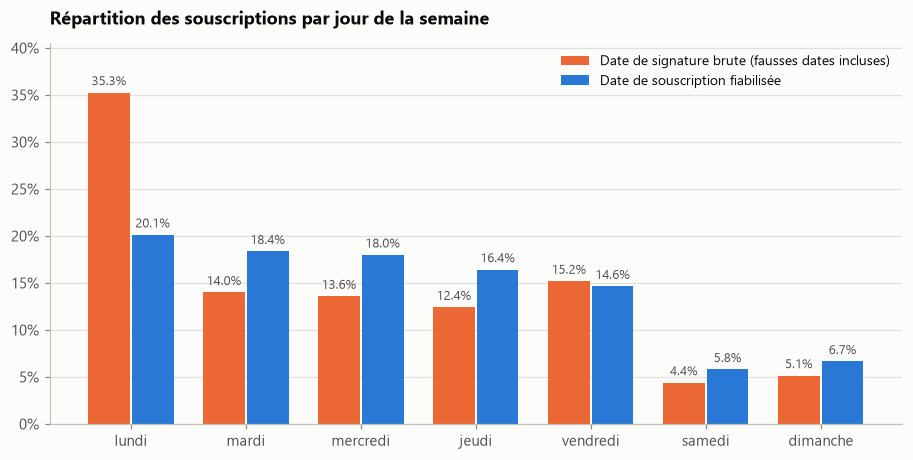

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(JOURS))
largeur = 0.36
barres_brut = ax.bar(x - largeur / 2 - 0.01, par_jour["part avec signature_date brute"], largeur,
                     color=PALETTE[1], label="Date de signature brute (fausses dates incluses)")
barres_fiable = ax.bar(x + largeur / 2 + 0.01, par_jour["part"], largeur,
                       color=PALETTE[0], label="Date de souscription fiabilisée")
for barres in (barres_brut, barres_fiable):
    ax.bar_label(barres, labels=[f"{v:.1%}" for v in barres.datavalues], padding=3, fontsize=8.5, color=ENCRE["secondaire"])
ax.set_xticks(x, JOURS)
ax.set_ylim(0, par_jour["part avec signature_date brute"].max() * 1.15)
format_pct(ax, "y")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Répartition des souscriptions par jour de la semaine")
sauver(fig, "p2_souscriptions_par_jour")
plt.show()

#### Souscriptions par jour et par heure (carte de chaleur)

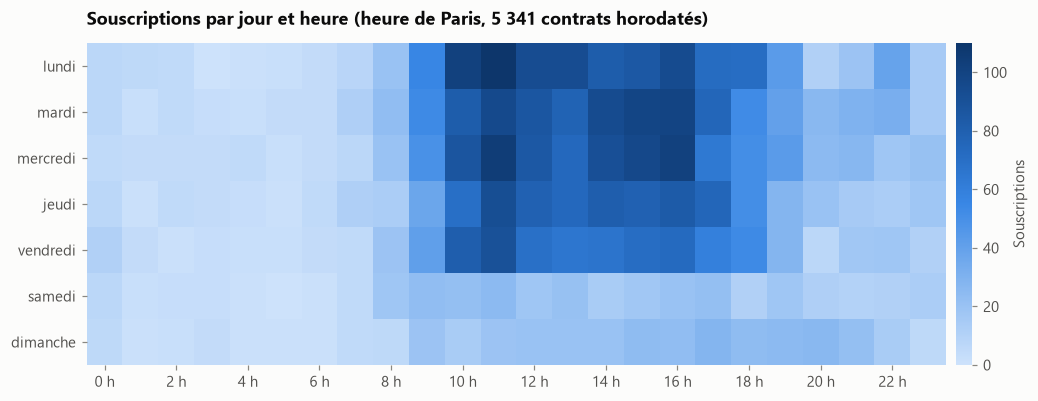

Heure de pointe : 11 h | part entre 9 h et 18 h : 74% | part après 18 h : 20%
Part des souscriptions le week-end : 12.5% (2 jours sur 7 = 28,6 % si uniforme)


In [6]:
horo = sous[sous["origine_date"].str.startswith("created_at")].copy()
horo["heure"] = horo["date_souscription"].dt.hour
grille = horo.pivot_table(index="jour", columns="heure", values="contract_id", aggfunc="size", fill_value=0, observed=False)
grille = grille.reindex(columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(grille.to_numpy(), aspect="auto", cmap=rampe_bleue())
ax.set_yticks(range(7), JOURS)
ax.set_xticks(range(0, 24, 2), [f"{h} h" for h in range(0, 24, 2)])
ax.grid(False)
ax.spines[:].set_visible(False)
barre = fig.colorbar(im, ax=ax, pad=0.01)
barre.set_label("Souscriptions")
barre.outline.set_visible(False)
ax.set_title(f"Souscriptions par jour et heure (heure de Paris, {nb(len(horo))} contrats horodatés)")
sauver(fig, "p2_souscriptions_jour_heure")
plt.show()

print(f"Heure de pointe : {horo['heure'].value_counts().idxmax()} h | part entre 9 h et 18 h : {horo['heure'].between(9, 17).mean():.0%}"
      f" | part après 18 h : {(horo['heure'] >= 18).mean():.0%}")
print(f"Part des souscriptions le week-end : {(~sous['jour'].isin(JOURS[:5])).mean():.1%} (2 jours sur 7 = 28,6 % si uniforme)")

#### **Réponse à la question**

Les prospects souscrivent le plus **le lundi (20,1 %)**, mais de peu : le mardi suit avec 18,4 %, puis le mercredi avec 18,0 %.

**Analyse**

- **Sans correction, on se serait trompé** : avec la date de signature brute, le lundi atteindrait 35 %, à cause de la fausse date du lundi 05/08/2024.
- **Les souscriptions baissent au fil de la semaine**, puis chutent le week-end : samedi et dimanche réunis ne font que 12,5 % du total.
- **On souscrit surtout aux heures de bureau** (pic à 11 h), mais **20 % des souscriptions ont lieu après 18 h**.
- **Le jour ne change pas la formule choisie** : la cotisation moyenne est à peu près la même tous les jours.

**Pistes business** : Il faut concentrer la publicité et les relances du dimanche soir au mardi, et renforcer le service client le lundi et le mardi.

## <u>2.2 Remboursements rapides (du 05/10/2026 au 18/10/2026)</u>

Le délai de remboursement se lit entre la date d'enregistrement de la demande (`created_at`) et la date de décision (`approved_date`). La partie 1 a montré (R10) que ces deux dates tombent **toujours le même jour** : le délai mesurable est de 0 jour pour 100 % des demandes. Toute demande approuvée l'est donc « en moins de 7 jours », et la question revient à compter les personnes remboursées sur la période.

**Choix** : Je compte donc les remboursements approuvés dont la date de décision est comprise entre le 05/10 et le 18/10/2026 inclus, avec un montant positif.

In [7]:
DEBUT, FIN = pd.Timestamp("2026-10-05"), pd.Timestamp("2026-10-18")
r = remboursements
approuves_fenetre = r[(r["is_approved"] == 1) & r["approved_date"].between(DEBUT, FIN)].copy()
approuves_fenetre["delai_jours"] = (approuves_fenetre["approved_date"] - approuves_fenetre["created_at"].dt.normalize()).dt.days
print("Délai de traitement (jours) :", approuves_fenetre["delai_jours"].value_counts().to_dict())

rembourses = approuves_fenetre[approuves_fenetre["amount_refund_mutual"] > 0]
rapides = rembourses[rembourses["delai_jours"] < 7]
reponse = pd.Series({
    "remboursements approuvés sur la période": len(approuves_fenetre),
    "dont avec un montant positif": len(rembourses),
    "dont traités en moins de 7 jours": len(rapides),
    "bénéficiaires distincts remboursés en moins de 7 jours": rapides["beneficiary_id"].nunique(),
    "adhérents distincts (user_id)": rapides["user_id"].nunique(),
    "montant total remboursé (€)": round(rapides["amount_refund_mutual"].sum(), 2),
})
reponse.to_frame("valeur")

Délai de traitement (jours) : {0: 1022}


,valeur
remboursements approuvés sur la période,1 022.00
dont avec un montant positif,1 004.00
dont traités en moins de 7 jours,1 004.00
bénéficiaires distincts remboursés en moins de 7 jours,741.00
adhérents distincts (user_id),716.00
montant total remboursé (€),34 745.68


#### Remboursements approuvés par jour, du 05/10 au 18/10/2026

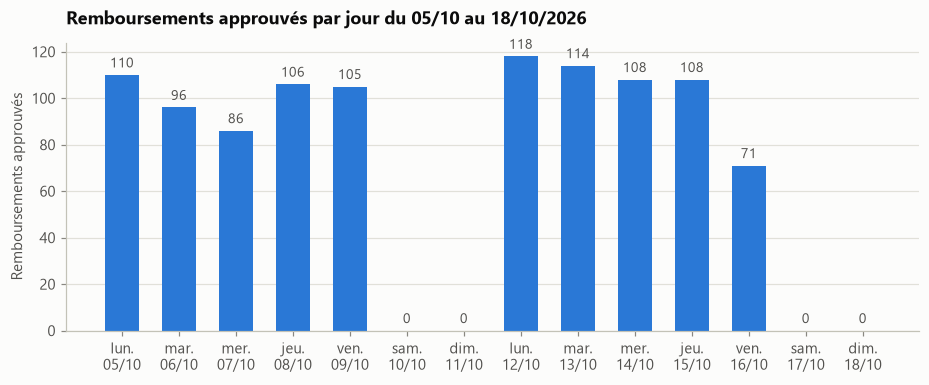

In [8]:
par_jour_fenetre = approuves_fenetre.groupby("approved_date").size().reindex(pd.date_range(DEBUT, FIN), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(par_jour_fenetre.index, par_jour_fenetre.values, width=0.6, color=PALETTE[0])
etiqueter_barres(ax, par_jour_fenetre.values, horizontal=False)
ax.set_xticks(par_jour_fenetre.index, [f"{JOURS[d.dayofweek][:3]}.\n{d:%d/%m}" for d in par_jour_fenetre.index])
ax.grid(axis="x", visible=False)
ax.set_ylabel("Remboursements approuvés")
ax.set_title("Remboursements approuvés par jour du 05/10 au 18/10/2026")
sauver(fig, "p2_remboursements_fenetre")
plt.show()

#### Lecture alternative : remboursement moins de 7 jours après le début du contrat

In [9]:
# Lecture alternative : remboursement reçu moins de 7 jours après la date d'effet du contrat
debut_contrat = rapides["contract_id"].map(contrats.set_index("contract_id")["start_date"])
apres_adhesion = rapides[(rapides["approved_date"] - debut_contrat).dt.days < 7]
print(f"Lecture alternative (moins de 7 jours après la date d'effet du contrat) : {apres_adhesion['beneficiary_id'].nunique()} bénéficiaires, "
      f"{len(apres_adhesion)} remboursements, {nb(apres_adhesion['amount_refund_mutual'].sum())} €")

Lecture alternative (moins de 7 jours après la date d'effet du contrat) : 12 bénéficiaires, 15 remboursements, 475 €


#### **Réponse à la question**

741 personnes ont été remboursées en moins de 7 jours entre le 05/10 et le 18/10/2026**, pour un total de 1 004 remboursements.

Je rappelle que :

- Le délai est toujours de 0 jour. La date enregistrée est celle où le gestionnaire traite la demande, pas celle où l'adhérent l'envoie. On ne connaît donc pas le vrai temps d'attente de l'adhérent. Pour le mesurer, il faudrait enregistrer la date d'envoi de la demande et la date du virement.
- Les 18 remboursements à 0 € ne sont pas comptés : la personne n'a rien reçu.
- Autre lecture possible : si l'on compte les 7 jours à partir du début du contrat, seules 12 personnes sont concernées.

## <u>2.3 et 2.4 Clients gagnés et clients perdus</u>

**Méthode.** Un client peut avoir plusieurs contrats, successifs (changement de formule) ou simultanés. Il faut reconstituer donc, pour chaque `user_id`, ses **périodes d'activité** : on fusionne ses contrats qui se chevauchent ou se suivent à moins de 31 jours d'écart.

- Un **client est gagné** au début d'une période (date d'effet du premier contrat) : « nouveau client » pour sa première période, « client reconquis » pour les suivantes.
- Un **client est perdu** à la fin d'une période, c'est-à-dire quand son **dernier contrat actif** est fermé. Un client qui change de formule n'est donc pas compté comme perdu.
- Les contrats **annulés avant leur date d'effet** sont exclus : le client n'a jamais été couvert. Les contrats à effet futur (après le 19/10/2026) aussi.

In [10]:
LOIN = pd.Timestamp("2100-01-01")
valides = contrats[~contrats["flag_annule_avant_effet"] & ~contrats["flag_effet_futur"]].copy()
print(f"Contrats exclus : {contrats['flag_annule_avant_effet'].sum()} annulés avant effet, {contrats['flag_effet_futur'].sum()} à effet futur")

iv = valides[["user_id", "contract_id", "start_date", "closed_date"]].sort_values(["user_id", "start_date"]).copy()
iv["fin"] = iv["closed_date"].fillna(LOIN)
iv["fin_precedente"] = iv.groupby("user_id")["fin"].transform(lambda x: x.cummax().shift())
iv["nouvelle_periode"] = iv["fin_precedente"].isna() | (iv["start_date"] > iv["fin_precedente"] + pd.Timedelta(days=31))
iv["periode"] = iv.groupby("user_id")["nouvelle_periode"].cumsum()

periodes = (iv.sort_values("fin").groupby(["user_id", "periode"])
              .agg(debut=("start_date", "min"), fin=("fin", "max"), contrat_final=("contract_id", "last"), nb_contrats=("contract_id", "size"))
              .reset_index())
periodes["type_gain"] = np.where(periodes["periode"] == 1, "Nouveau client", "Client reconquis")
periodes["perdu"] = periodes["fin"] < LOIN
periodes["anciennete_mois"] = ((periodes["fin"].where(periodes["perdu"]) - periodes["debut"]).dt.days / 30.44)
print(f"{nb(periodes['user_id'].nunique())} clients, {nb(len(periodes))} périodes d'activité "
      f"({(periodes['type_gain'] == 'Client reconquis').sum()} reconquêtes), {nb(periodes['perdu'].sum())} pertes, "
      f"{nb((~periodes['perdu']).sum())} clients actifs au 19/10/2026")

Contrats exclus : 324 annulés avant effet, 92 à effet futur
11 706 clients, 11 771 périodes d'activité (65 reconquêtes), 6 493 pertes, 5 278 clients actifs au 19/10/2026


### Analyse des motifs de perte de contrats et détection des clôtures groupées à partir de l’historique de paiement

In [11]:
# Motif probable de la perte, déduit de l'historique de paiement du dernier contrat

trois_derniers = stripe.sort_values("created_at").groupby("contract_id").tail(3)
derniers_en_echec = trois_derniers.groupby("contract_id")["status"].agg(lambda x: (x == "Failed").all())
info = contrats.set_index("contract_id")
pertes = periodes[periodes["perdu"]].copy()
cf = pertes["contrat_final"]
sans_tx = cf.map(info["flag_sans_transaction"])
impaye = cf.map(info["flag_jamais_encaisse"]) | cf.map(derniers_en_echec).fillna(False).astype(bool)
pertes["motif"] = np.select(
    [sans_tx, impaye, pertes["anciennete_mois"] < 3],
    ["Sans historique de paiement", "Impayés", "Départ dans les 3 premiers mois"], default="Résiliation après 3 mois")
pertes["mois"] = pertes["fin"].dt.to_period("M")

# Clôtures groupées : au moins 50 contrats fermés à la même seconde, hors minuit (échéance de fin de mois)

horodatage = pertes["fin"]
taille_lot = horodatage.map(horodatage.value_counts())
pertes["cloture_groupee"] = (taille_lot >= 50) & (horodatage != horodatage.dt.normalize())
pertes["reprise"] = cf.map(info["flag_migration"])
print(pertes["motif"].value_counts().to_string())
print("\nClôtures groupées (même seconde, >= 50 clients) :")
lots = pertes[pertes["cloture_groupee"]].groupby("fin").agg(
    clients=("user_id", "size"),
    impayes=("motif", lambda x: (x == "Impayés").mean()),
    sans_historique=("motif", lambda x: (x == "Sans historique de paiement").mean()),
    resiliation=("motif", lambda x: (x == "Résiliation après 3 mois").mean()),
    issus_de_la_reprise=("reprise", "mean"),
    produit_principal=("contrat_final", lambda x: x.map(info["product_name"]).mode()[0]))
lots.style.format({c: "{:.0%}" for c in ["impayes", "sans_historique", "resiliation", "issus_de_la_reprise"]})

motif
Résiliation après 3 mois           3640
Impayés                            1576
Sans historique de paiement         880
Départ dans les 3 premiers mois     397

Clôtures groupées (même seconde, >= 50 clients) :


,clients,impayes,sans_historique,resiliation,issus_de_la_reprise,produit_principal
fin,,,,,,
2026-02-02 10:59:04,105,65%,11%,24%,30%,Vita Découverte
2026-04-21 19:08:47,140,0%,99%,1%,99%,Vita Découverte
2026-06-08 08:54:29,260,1%,98%,1%,98%,Vita Découverte
2026-06-18 10:50:12,109,64%,0%,33%,44%,Vita Découverte


In [12]:
mois = pd.period_range("2023-01", MOIS_EN_COURS, freq="M")
gains = periodes.assign(mois=periodes["debut"].dt.to_period("M")).pivot_table(
    index="mois", columns="type_gain", values="user_id", aggfunc="size", fill_value=0).reindex(mois, fill_value=0)
gains["Total"] = gains.sum(axis=1)
perdus = pertes.pivot_table(index="mois", columns="motif", values="user_id", aggfunc="size", fill_value=0).reindex(mois, fill_value=0)
perdus["Total"] = perdus.sum(axis=1)

suivi = pd.DataFrame({"gagnés": gains["Total"], "perdus": perdus["Total"]})
suivi["solde"] = suivi["gagnés"] - suivi["perdus"]
suivi["clients actifs fin de mois"] = suivi["solde"].cumsum()
suivi["taux de perte mensuel"] = suivi["perdus"] / suivi["clients actifs fin de mois"].shift()
assert suivi["clients actifs fin de mois"].iloc[-1] == (~periodes["perdu"]).sum()

annuel = suivi.groupby(suivi.index.year)[["gagnés", "perdus", "solde"]].sum()
annuel["clients actifs fin de période"] = suivi.groupby(suivi.index.year)["clients actifs fin de mois"].last()
annuel.index.name = "année (2026 : jusqu'au 19/10)"
annuel

,gagnés,perdus,solde,clients actifs fin de période
année (2026 : jusqu'au 19/10),,,,
2023,869,36,833,833
2024,3466,795,2671,3504
2025,4529,2141,2388,5892
2026,2907,3521,-614,5278


### 2.3 Évolution mensuelle des clients gagnés

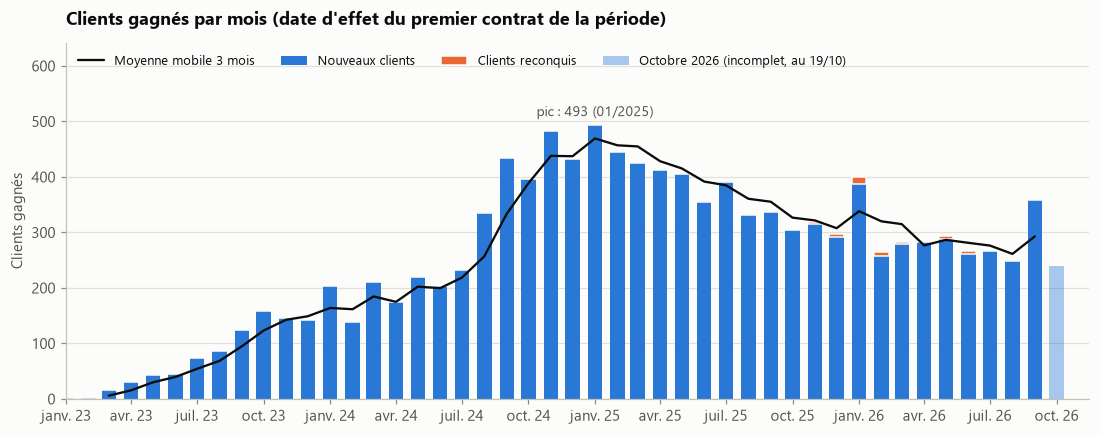

In [13]:
x = suivi.index.to_timestamp()
en_cours = suivi.index == MOIS_EN_COURS
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(x[~en_cours], gains["Nouveau client"][~en_cours], width=20, color=PALETTE[0], label="Nouveaux clients")
ax.bar(x[~en_cours], gains["Client reconquis"][~en_cours], width=20, bottom=gains["Nouveau client"][~en_cours],
       color=PALETTE[1], label="Clients reconquis", edgecolor=ENCRE["fond"], linewidth=1)
ax.bar(x[en_cours], gains["Total"][en_cours], width=20, color=PALETTE[0], alpha=0.4, label="Octobre 2026 (incomplet, au 19/10)")
moyenne_mobile = gains["Total"].where(~en_cours).rolling(3).mean()
ax.plot(x, moyenne_mobile, color=ENCRE["principale"], linewidth=1.5, label="Moyenne mobile 3 mois")
pic = gains["Total"].idxmax()
ax.annotate(f"pic : {gains['Total'].max()} ({pic.strftime('%m/%Y')})", (pic.to_timestamp(), gains["Total"].max()),
            xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9, color=ENCRE["secondaire"])
axe_mensuel(ax)
ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2026-11-15"))
ax.set_ylim(0, gains["Total"].max() * 1.3)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=4, fontsize=8.5)
ax.set_ylabel("Clients gagnés")
ax.set_title("Clients gagnés par mois (date d'effet du premier contrat de la période)")
sauver(fig, "p2_clients_gagnes")
plt.show()

In [14]:
def moyenne_mensuelle(serie, debut, fin):
    return serie.loc[pd.Period(debut, "M"):pd.Period(fin, "M")].mean()

print(f"Moyenne mensuelle des clients gagnés : 2024 = {moyenne_mensuelle(gains['Total'], '2024-01', '2024-12'):.0f} | "
      f"1er sem. 2025 = {moyenne_mensuelle(gains['Total'], '2025-01', '2025-06'):.0f} | "
      f"2nd sem. 2025 = {moyenne_mensuelle(gains['Total'], '2025-07', '2025-12'):.0f} | "
      f"2026 (janv.-sept.) = {moyenne_mensuelle(gains['Total'], '2026-01', '2026-09'):.0f}")
print("Mois les plus forts :", gains["Total"].nlargest(4).rename(lambda p: p.strftime("%m/%Y")).to_dict())
canaux = (valides.assign(an=valides["start_date"].dt.year)
          .pivot_table(index="canal_acquisition", columns="an", values="contract_id", aggfunc="size", fill_value=0))
canaux

Moyenne mensuelle des clients gagnés : 2024 = 289 | 1er sem. 2025 = 423 | 2nd sem. 2025 = 332 | 2026 (janv.-sept.) = 296
Mois les plus forts : {'01/2025': 493, '11/2024': 483, '02/2025': 446, '09/2024': 434}


an,2023,2024,2025,2026
canal_acquisition,,,,
Email / CRM,0,0,122,206
Non renseigné,869,3488,3912,1376
"Organique (fiche Google, IA, avis, site)",0,0,20,30
Parrainage,0,0,98,125
Partenaires et influenceurs,0,0,16,30
Publicité moteur de recherche,0,0,233,768
Réseaux sociaux,0,0,163,434


**Lecture des résultats**

- **Belle croissance jusqu'en janvier 2025** : on passe de quelques dizaines de nouveaux clients par mois en 2023 à un pic de **493** en janvier 2025, avec une vraie accélération depuis l'été 2024.
- **Ralentissement depuis le printemps 2025** : environ 423 clients gagnés par mois au premier semestre 2025, 332 au second, puis 296 sur janvier-septembre 2026. Soit **30 % de moins** qu'au pic.
- **Saisonnalité** : janvier est toujours un bon mois (changements de complémentaire au 1er janvier). Septembre aussi en 2024 et 2026, mais pas en 2025. Le rebond de septembre 2026 reste à confirmer.
- **Reconquêtes** : marginales, 65 sur toute la période.
- **Canaux** : suivis seulement depuis 2025. En 2026, la pub sur les moteurs de recherche (768 contrats) et les réseaux sociaux (434) sont en tête, devant l'emailing (206) et le parrainage (125). Mais **46 % des contrats 2026 n'ont pas de source**, donc impossible de dire quel canal explique le ralentissement.

### 2.4 Évolution mensuelle des clients perdus

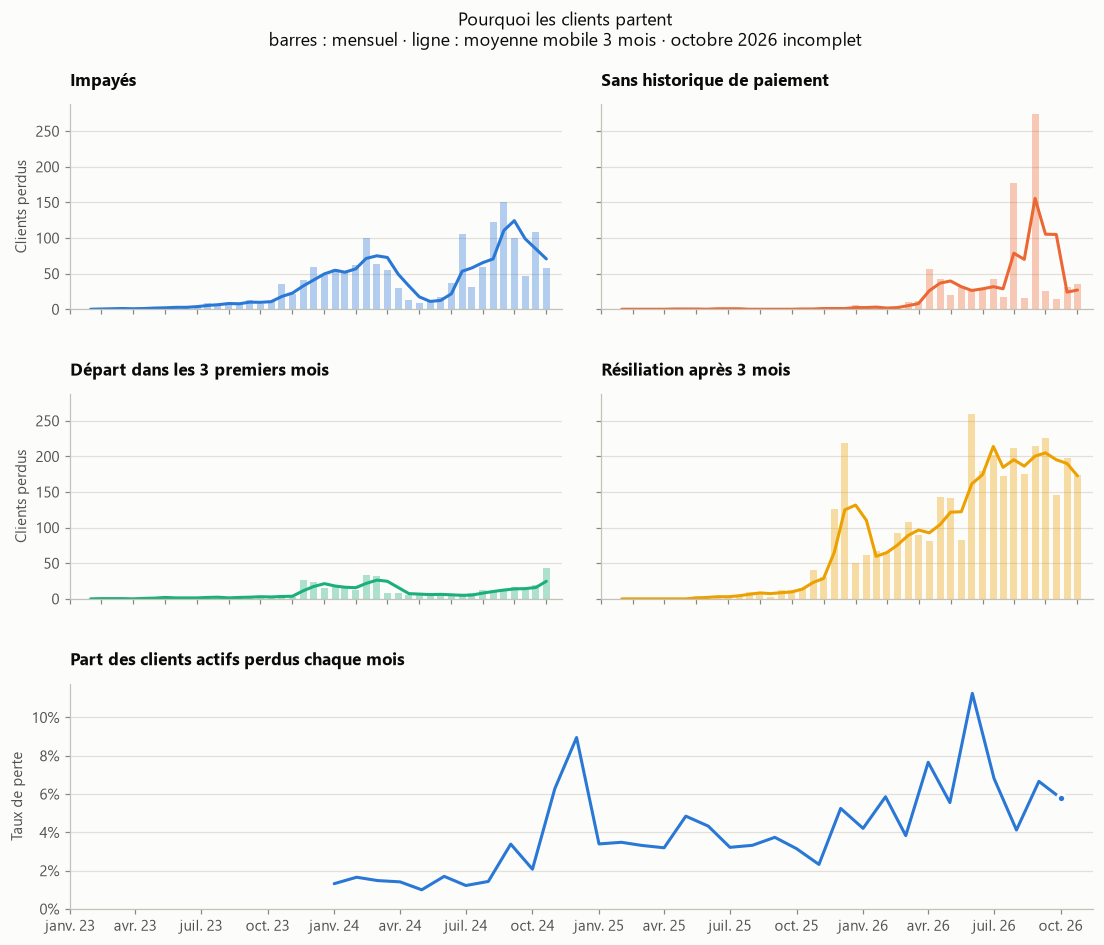

In [15]:
motifs = ["Impayés", "Sans historique de paiement", "Départ dans les 3 premiers mois", "Résiliation après 3 mois"]
fig = plt.figure(figsize=(12, 9.5))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.1], hspace=0.4, wspace=0.08)

axes_motifs = []
for i, (motif, couleur) in enumerate(zip(motifs, PALETTE)):
    ax = fig.add_subplot(gs[i // 2, i % 2],
                         sharex=axes_motifs[0] if axes_motifs else None,
                         sharey=axes_motifs[0] if axes_motifs else None)
    ax.bar(x, perdus[motif], width=20, color=couleur, alpha=0.35)
    ax.plot(x, perdus[motif].rolling(3).mean(), color=couleur, linewidth=2)
    ax.set_title(motif, fontsize=11, loc="left")
    ax.grid(axis="x", visible=False)
    ax.tick_params(labelbottom=False)
    if i % 2 == 1:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel("Clients perdus")
    axes_motifs.append(ax)

ax = fig.add_subplot(gs[2, :], sharex=axes_motifs[0])
taux = suivi["taux de perte mensuel"].where(suivi.index >= pd.Period("2024-01", "M"))
ax.plot(x, taux, color=PALETTE[0], linewidth=2)
ax.scatter(x[-1:], taux.iloc[-1:], s=30, color=PALETTE[0], zorder=3,
           edgecolor=ENCRE["fond"], linewidth=2)
format_pct(ax, "y")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Taux de perte")
ax.set_title("Part des clients actifs perdus chaque mois", fontsize=11, loc="left")
axe_mensuel(ax)
ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2026-11-15"))

fig.suptitle("Pourquoi les clients partent\n"
             "barres : mensuel · ligne : moyenne mobile 3 mois · octobre 2026 incomplet",
             fontsize=12, y=0.97)
sauver(fig, "p2_clients_perdus")
plt.show()

###  Solde mensuel et ancienneté des clients perdus

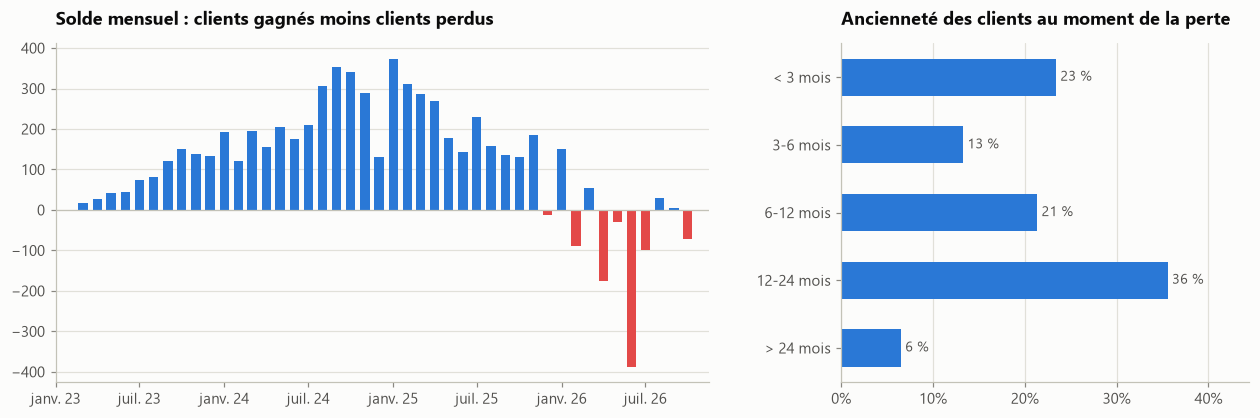

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.25})
ax = axes[0]
couleurs_solde = np.where(suivi["solde"] >= 0, PALETTE[0], PALETTE[7])
ax.bar(x, suivi["solde"], width=20, color=couleurs_solde)
ax.axhline(0, color=ENCRE["axe"], linewidth=0.8)
axe_mensuel(ax, mois=(1, 7))
ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2026-11-15"))
ax.grid(axis="x", visible=False)
ax.set_title("Solde mensuel : clients gagnés moins clients perdus")

ax = axes[1]
tranches = pd.cut(pertes["anciennete_mois"], [-0.01, 3, 6, 12, 24, 1000], labels=["< 3 mois", "3-6 mois", "6-12 mois", "12-24 mois", "> 24 mois"])
repartition = tranches.value_counts(normalize=True).sort_index()
ax.barh(repartition.index.astype(str), repartition.values, height=0.55, color=PALETTE[0])
etiqueter_barres(ax, repartition.values * 100, fmt="{:.0f} %")
ax.invert_yaxis()
format_pct(ax, "x")
ax.set_xlim(0, repartition.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Ancienneté des clients au moment de la perte")
sauver(fig, "p2_solde_anciennete")
plt.show()


In [17]:
print(f"Ancienneté médiane à la perte : {pertes['anciennete_mois'].median():.1f} mois")
print("Répartition de l'ancienneté :", repartition.map("{:.0%}".format).to_dict())
print(f"Clients actifs : {nb(suivi.loc['2025-12', 'clients actifs fin de mois'])} fin 2025 -> {nb(suivi.iloc[-1]['clients actifs fin de mois'])} au 19/10/2026")
print("Pertes hors clôtures groupées, moyenne mensuelle 2026 :", round(pertes[~pertes["cloture_groupee"] & (pertes["fin"].dt.year == 2026)].groupby("mois").size().mean()))
print("Taux de perte mensuel moyen :", {a: f"{suivi.loc[str(a), 'taux de perte mensuel'].mean():.1%}" for a in [2024, 2025, 2026]})
print("Mois au solde négatif en 2026 :", (suivi.loc["2026", "solde"] < 0).sum(), "sur", len(suivi.loc["2026"]))
print("Part des motifs par année :")
pertes.assign(an=pertes["fin"].dt.year).pivot_table(index="motif", columns="an", values="user_id", aggfunc="size", fill_value=0).loc[motifs]

Ancienneté médiane à la perte : 9.7 mois
Répartition de l'ancienneté : {'< 3 mois': '23%', '3-6 mois': '13%', '6-12 mois': '21%', '12-24 mois': '36%', '> 24 mois': '6%'}
Clients actifs : 5 892 fin 2025 -> 5 278 au 19/10/2026
Pertes hors clôtures groupées, moyenne mensuelle 2026 : 291
Taux de perte mensuel moyen : {2024: '2.7%', 2025: '3.6%', 2026: '6.2%'}
Mois au solde négatif en 2026 : 6 sur 10
Part des motifs par année :


an,2023,2024,2025,2026
motif,,,,
Impayés,16,226,516,818
Sans historique de paiement,3,4,213,660
Départ dans les 3 premiers mois,8,76,169,144
Résiliation après 3 mois,9,489,1243,1899


**Lecture des résultats**

- **Les pertes augmentent plus vite que le portefeuille.** Le taux de perte mensuel moyen passe de 2,7 % en 2024 à 3,6 % en 2025, puis 6,2 % en 2026. Avec des recrutements en baisse, le **solde est négatif 6 mois sur 10 en 2026** : 5 892 clients actifs fin 2025, 5 278 au 19/10/2026 (-614, soit -10 %).
- **Une partie de cette hausse est administrative.** Quatre clôtures groupées (au moins 50 contrats fermés à la même seconde) pèsent sur 2026 :
  - **21/04 (140 clients) et 08/06 (260 clients, pic de juin)** : 98-99 % de contrats issus de la reprise, sans transaction Stripe. C'est une purge de contrats hérités, pas des départs de clients payants.
  - **02/02 (105) et 18/06 (109)** : aux deux tiers des impayés, traités en lot.

  Hors clôtures groupées, on perd 291 clients par mois en 2026 pour 296 gagnés : **le portefeuille stagne plus qu'il ne s'effondre**.
- **Motifs.** Les résiliations après 3 mois dominent (3 640, soit 56 % des pertes). Les **impayés pèsent un quart des pertes** (1 576) et ont été multipliés par 3,6 en deux ans : 226 en 2024, 516 en 2025, 818 en 2026 (à fin octobre).
- **Ancienneté.** 23 % des clients partent avant 3 mois et **36 % entre 12 et 24 mois**, probablement car la résiliation est libre après un an. Ancienneté médiane à la perte : 9,7 mois.
- Les clôtures à minuit en fin de mois correspondent vraisemblablement à des résiliations à échéance mensuelle.

**Pistes** : Il faut sécuriser l'encaissement (prélèvement SEPA plutôt que carte, relances avant échéance, nouvelle tentative après les dates de versement des salaires) ; soigner l'activation durant les 3 premiers mois ; préparer le premier anniversaire (bilan des garanties, formule mieux adaptée avant toute résiliation).

## <u>2.5 Montants remboursés par mois depuis 2024</u>

La table Remboursements ne commence que le **05/06/2025**. Il n'existe aucun remboursement en 2024 ni début 2025. L'historique antérieur n'est pas dans la base de données reçue. Le graphique couvre donc toute la période demandée, mais ne peut montrer que juin 2025 à octobre 2026.

In [18]:
rembourse = remboursements[(remboursements["is_approved"] == 1) & (remboursements["amount_refund_mutual"] > 0)].copy()
rembourse["mois"] = rembourse["approved_date"].dt.to_period("M")
print("Premier remboursement :", rembourse["approved_date"].min().date(), "| dernier :", rembourse["approved_date"].max().date())

mensuel = rembourse.groupby("mois").agg(montant=("amount_refund_mutual", "sum"), remboursements=("claim_id", "size"),
                                        beneficiaires=("beneficiary_id", "nunique"))
mensuel["montant moyen"] = mensuel["montant"] / mensuel["remboursements"]
mensuel = mensuel.reindex(pd.period_range("2024-01", MOIS_EN_COURS, freq="M"))
mensuel.dropna().style.format({"montant": "{:,.0f} €", "remboursements": "{:,.0f}", "beneficiaires": "{:,.0f}", "montant moyen": "{:.1f} €"}, thousands=" ")

Premier remboursement : 2025-06-05 | dernier : 2026-10-19


,montant,remboursements,beneficiaires,montant moyen
2025-06,81 551 €,2 082,1 356,39.2 €
2025-07,86 299 €,2 191,1 395,39.4 €
2025-08,63 840 €,1 777,1 222,35.9 €
2025-09,85 281 €,2 309,1 454,36.9 €
2025-10,95 597 €,2 770,1 681,34.5 €
2025-11,108 424 €,2 807,1 719,38.6 €
2025-12,114 128 €,3 053,1 694,37.4 €
2026-01,91 205 €,2 474,1 587,36.9 €
2026-02,78 409 €,2 031,1 355,38.6 €
2026-03,128 699 €,3 413,2 036,37.7 €


### Graphique des montants remboursés par la mutuelle

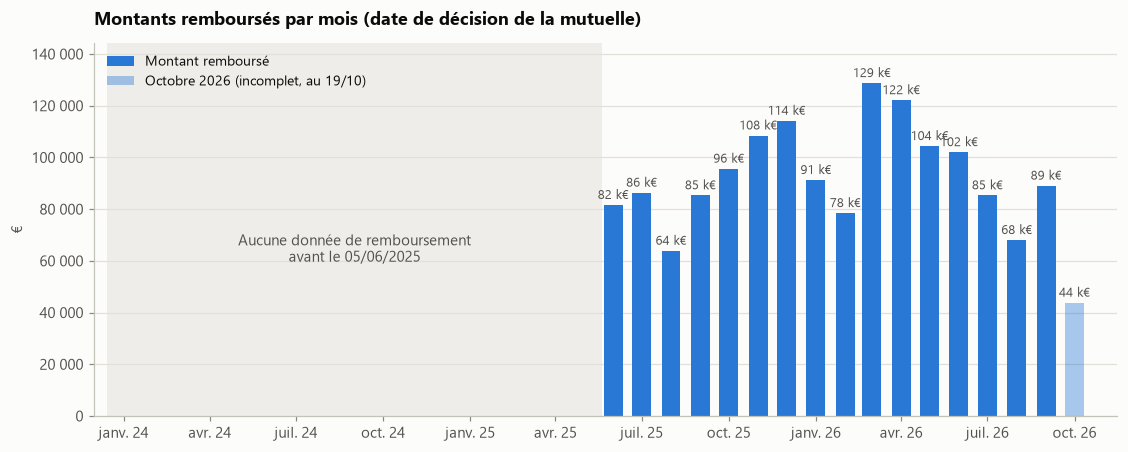

In [19]:
xm = mensuel.index.to_timestamp()
plein = mensuel["montant"].notna() & (mensuel.index != MOIS_EN_COURS)
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.bar(xm[plein], mensuel["montant"][plein], width=20, color=PALETTE[0], label="Montant remboursé")
ax.bar(xm[mensuel.index == MOIS_EN_COURS], mensuel["montant"][mensuel.index == MOIS_EN_COURS], width=20,
       color=PALETTE[0], alpha=0.4, label="Octobre 2026 (incomplet, au 19/10)")
ax.axvspan(pd.Timestamp("2023-12-15"), pd.Timestamp("2025-05-20"), color=ENCRE["grille"], alpha=0.5, linewidth=0)
ax.text(pd.Timestamp("2024-09-01"), mensuel["montant"].max() * 0.5, "Aucune donnée de remboursement\navant le 05/06/2025",
        ha="center", va="center", fontsize=10, color=ENCRE["secondaire"])


for periode, valeur in mensuel["montant"].dropna().items():
    ax.annotate(f"{valeur / 1000:.0f} k€", (periode.to_timestamp(), valeur),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, color=ENCRE["secondaire"])

axe_mensuel(ax)
ax.set_xlim(pd.Timestamp("2023-12-01"), pd.Timestamp("2026-11-15"))
ax.set_ylim(0, mensuel["montant"].max() * 1.12)
format_milliers(ax, "y")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_ylabel("€")
ax.set_title("Montants remboursés par mois (date de décision de la mutuelle)", loc="left")
sauver(fig, "p2_montants_rembourses")
plt.show()

In [20]:
complets = mensuel["montant"][plein]
print(f"Total remboursé : {nb(rembourse['amount_refund_mutual'].sum())} € | moyenne mensuelle (mois complets) : {nb(complets.mean())} €")
print(f"Montant médian d'un remboursement : {rembourse['amount_refund_mutual'].median():.2f} € | moyen : {rembourse['amount_refund_mutual'].mean():.2f} €")
print(f"Mois complets : de {nb(complets.min())} € ({complets.idxmin().strftime('%m/%Y')}) à {nb(complets.max())} € ({complets.idxmax().strftime('%m/%Y')})")
print(f"Part des 58 montants > 500 € dans le total : {rembourse.loc[rembourse['flag_montant_extreme'], 'amount_refund_mutual'].sum() / rembourse['amount_refund_mutual'].sum():.1%}")
par_client = (mensuel["montant"] / suivi["clients actifs fin de mois"]).loc["2025-06":"2026-09"]
print(f"Montant remboursé par client actif et par mois : {par_client.loc['2025-06':'2025-12'].mean():.2f} € (juin-déc. 2025)"
      f" -> {par_client.loc['2026-01':'2026-09'].mean():.2f} € (janv.-sept. 2026)")

Total remboursé : 1 547 862 € | moyenne mensuelle (mois complets) : 94 007 €
Montant médian d'un remboursement : 26.64 € | moyen : 37.73 €
Mois complets : de 63 840 € (08/2025) à 128 699 € (03/2026)
Part des 58 montants > 500 € dans le total : 3.3%
Montant remboursé par client actif et par mois : 16.26 € (juin-déc. 2025) -> 16.98 € (janv.-sept. 2026)


**Lecture des résultats**

- Depuis juin 2025, la mutuelle rembourse en moyenne **environ 94 000 € par mois** (de 64 k€ à 129 k€, 1,55 M€ au total). Le remboursement médian est d'environ 27 € : beaucoup de petits montants, peu de gros.
- **Saisonnalité nette** :
  - **creux en août**, en 2025 comme en 2026 (probablement les vacances) ;
  - **hausse en novembre-décembre 2025**, vraisemblablement la consommation des forfaits annuels avant leur remise à zéro au 1er janvier ;
  - **pic en mars-avril 2026** (129 k€ puis 122 k€), peut-être lié aux épidémies de fin d'hiver.
- **Par client actif, le montant remboursé augmente légèrement** : 16,3 € par mois de juin à décembre 2025, 17,0 € de janvier à septembre 2026 (+4 %). Si les clients qui partent consomment peu, le coût moyen du portefeuille monte.
- Les 58 remboursements de plus de 500 € (flag R9) pèsent peu dans le total et ne changent pas la tendance.

## <u>2.6 Question bonus : deux statistiques clés pour le business</u>

Pour une mutuelle, deux indicateurs pilotent la santé économique : **ce qu'elle reverse par rapport à ce qu'elle encaisse**, et **sa capacité à encaisser les cotisations**.

### Statistique 1 : ratio remboursements/cotisations encaissées c'est-à-dire le ratio S/P apparent

On calcule le S/P chaque mois, mais seulement sur les mois pour lesquels on a les deux données : les remboursements (mutuelle) et les cotisations (Stripe). Cela donne la période de juin 2025 à septembre 2026. Octobre 2026 est exclu : le mois n'est pas terminé et les données Stripe s'arrêtent au 05/10/2026.

S/P apparent sur la période : 28.9% | min 19.0% (08/2026) | max 36.7% (03/2026)


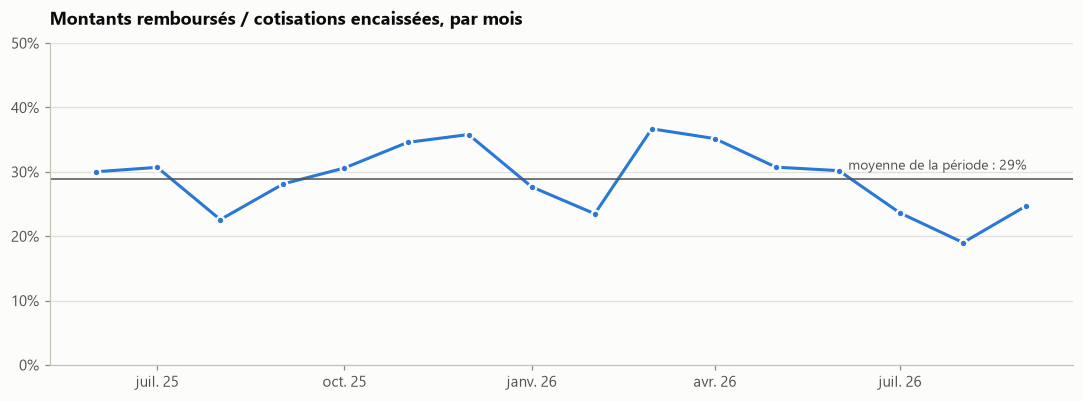

,cotisations encaissées,montants remboursés,S/P apparent
2025-06,271 673 €,81 551 €,30.0%
2025-07,281 139 €,86 299 €,30.7%
2025-08,282 700 €,63 840 €,22.6%
2025-09,303 099 €,85 281 €,28.1%
2025-10,312 427 €,95 597 €,30.6%
2025-11,313 573 €,108 424 €,34.6%
2025-12,318 831 €,114 128 €,35.8%
2026-01,329 590 €,91 205 €,27.7%
2026-02,333 899 €,78 409 €,23.5%
2026-03,350 838 €,128 699 €,36.7%


In [21]:
encaisse = stripe[(stripe["status"] == "Paid") & ~stripe["flag_contrat_inconnu"]]
cotisations = encaisse.groupby(encaisse["created_at"].dt.to_period("M"))["montant_net"].sum()
sp = pd.DataFrame({"cotisations encaissées": cotisations, "montants remboursés": mensuel["montant"]}).loc["2025-06":"2026-09"]
sp["S/P apparent"] = sp["montants remboursés"] / sp["cotisations encaissées"]
total_sp = sp["montants remboursés"].sum() / sp["cotisations encaissées"].sum()
print(f"S/P apparent sur la période : {total_sp:.1%} | min {sp['S/P apparent'].min():.1%} ({sp['S/P apparent'].idxmin().strftime('%m/%Y')})"
      f" | max {sp['S/P apparent'].max():.1%} ({sp['S/P apparent'].idxmax().strftime('%m/%Y')})")

fig, ax = plt.subplots(figsize=(12, 3.8))
xs = sp.index.to_timestamp()
ax.plot(xs, sp["S/P apparent"], color=PALETTE[0], marker="o", markersize=5, markeredgecolor=ENCRE["fond"], markeredgewidth=1.5)
ax.axhline(total_sp, color=ENCRE["secondaire"], linewidth=1)
ax.annotate(f"moyenne de la période : {total_sp:.0%}", (xs[-1], total_sp), xytext=(0, 6), textcoords="offset points",
            ha="right", fontsize=9, color=ENCRE["secondaire"])
axe_mensuel(ax)
format_pct(ax, "y")
ax.set_ylim(0, 0.5)
ax.grid(axis="x", visible=False)
ax.set_title("Montants remboursés / cotisations encaissées, par mois")
sauver(fig, "p2_bonus_sp")
plt.show()
sp.style.format({"cotisations encaissées": "{:,.0f} €", "montants remboursés": "{:,.0f} €", "S/P apparent": "{:.1%}"}, thousands=" ")

**Lecture des résultats**

- **La mutuelle reverse en moyenne 29 % des cotisations encaissées**, avec des pointes à 35-37 % (fin 2025, mars-avril 2026) et des creux l'été. C'est bas : pour une complémentaire santé, ce ratio dépasse habituellement 50 %.
- **Ce chiffre sous-estime la réalité** (S/P apparent), car :
  - les cotisations incluent des sommes qui ne servent pas à rembourser (taxes, rémunération de NostrumCare) ;
  - les remboursements payés directement par l'assureur (demandes télétransmises, motif `TELETRANSMITTED`) ne figurent pas dans la table.
- **Son niveau est donc à interpréter avec prudence, mais sa tendance est fiable** : environ 30 % en 2025, 28 % en 2026. Les remboursements évoluent au même rythme que les cotisations.
- **Suivi chaque mois, il permet de repérer tôt une dérive de la sinistralité** (épidémie, anti-sélection, fraude) et d'ajuster les tarifs en conséquence.

### Statistique 2 : qualité d'encaissement des cotisations

On suit deux chiffres chaque mois :

- **Les prélèvements qui échouent** : sur toutes les tentatives de paiement, combien sont refusées. Cela mesure les problèmes techniques du système de paiement.
- **Les impayés** : sur tous les clients facturés, combien n'ont **jamais réussi à payer** dans le mois. Cela mesure l'argent réellement perdu.

On compte les clients et non les tentatives, car un même client peut être prélevé plusieurs fois (le système réessaie automatiquement). Compter chaque tentative ferait paraître les impayés plus nombreux qu'ils ne sont.

In [22]:
st = stripe[~stripe["flag_contrat_inconnu"] & stripe["status"].isin(["Paid", "Failed"])].copy()
st["mois"] = st["created_at"].dt.to_period("M")
echec_tentatives = st.groupby("mois")["status"].agg(lambda x: (x == "Failed").mean()).loc["2024-01":"2026-09"]
par_contrat_mois = st.groupby(["mois", "contract_id"]).agg(paye=("status", lambda x: (x == "Paid").any()), montant=("amount", "max"))
impayes = (1 - par_contrat_mois.groupby("mois")["paye"].mean()).loc["2024-01":"2026-09"]
non_recouvre = par_contrat_mois[~par_contrat_mois["paye"]].groupby("mois")["montant"].sum().loc["2024-01":"2026-09"]

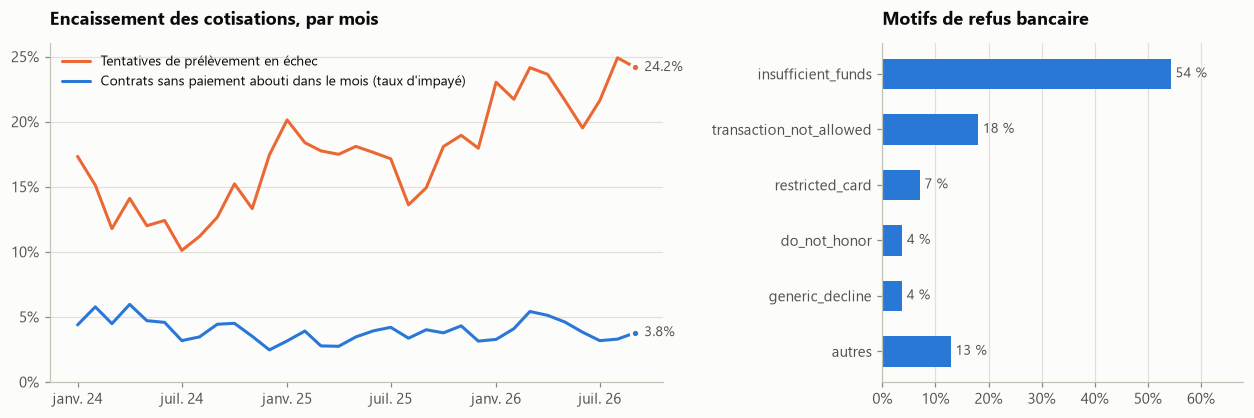

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.7, 1], "wspace": 0.45})
ax = axes[0]
for serie, couleur, libelle in [(echec_tentatives, PALETTE[1], "Tentatives de prélèvement en échec"),
                                (impayes, PALETTE[0], "Contrats sans paiement abouti dans le mois (taux d'impayé)")]:
    xs_ = serie.index.to_timestamp()
    ax.plot(xs_, serie.values, color=couleur, label=libelle)
    ax.scatter(xs_[-1:], serie.values[-1:], s=30, color=couleur, zorder=3, edgecolor=ENCRE["fond"], linewidth=2)
    ax.annotate(f"{serie.iloc[-1]:.1%}", (xs_[-1], serie.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=ENCRE["secondaire"])
axe_mensuel(ax, mois=(1, 7))
format_pct(ax, "y")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("Encaissement des cotisations, par mois")

ax = axes[1]
motifs_refus = stripe.loc[stripe["status"] == "Failed", "decline_reason"].value_counts(normalize=True)
top = pd.concat([motifs_refus.head(5), pd.Series({"autres": motifs_refus.iloc[5:].sum()})])
ax.barh(top.index, top.values, height=0.55, color=PALETTE[0])
etiqueter_barres(ax, top.values * 100, fmt="{:.0f} %")
ax.invert_yaxis()
format_pct(ax, "x")
ax.set_xlim(0, top.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Motifs de refus bancaire")
sauver(fig, "p2_bonus_impayes")
plt.show()

In [24]:
print("Part des tentatives en échec, moyenne :", {a: f"{echec_tentatives.loc[str(a)].mean():.1%}" for a in [2024, 2025, 2026]})
print("Taux d'impayé moyen :", {a: f"{impayes.loc[str(a)].mean():.1%}" for a in [2024, 2025, 2026]})
print("Tentatives par contrat facturé :", {a: round(st[st['mois'].dt.year == a].shape[0] / par_contrat_mois.loc[str(a)].shape[0], 2) for a in [2024, 2025, 2026]})
print(f"Cotisations non recouvrées dans le mois (une échéance par contrat impayé) : {nb(non_recouvre.loc['2026'].mean())} € par mois en 2026"
      f", soit {non_recouvre.loc['2026'].sum() / cotisations.loc['2026-01':'2026-09'].sum():.1%} des cotisations encaissées")

Part des tentatives en échec, moyenne : {2024: '13.6%', 2025: '17.5%', 2026: '22.7%'}
Taux d'impayé moyen : {2024: '4.3%', 2025: '3.6%', 2026: '4.1%'}
Tentatives par contrat facturé : {2024: 1.16, 2025: 1.19, 2026: 1.28}
Cotisations non recouvrées dans le mois (une échéance par contrat impayé) : 16 145 € par mois en 2026, soit 4.7% des cotisations encaissées


**Lecture des résultats**

- **De plus en plus de prélèvements échouent** : 13,6 % des tentatives en 2024, 17,5 % en 2025, 22,7 % en 2026. Aujourd'hui, plus d'une tentative sur cinq est refusée.
- **Pourtant, les impayés restent stables, autour de 4 %.** Le système réessaie automatiquement et finit par encaisser la plupart des échéances (1,28 tentative par contrat facturé en 2026, contre 1,16 en 2024). Ça tient, mais à un coût : plus de frais de transaction, plus de relances, et des clients qui se fragilisent.
- **Environ 16 000 € de cotisations ne sont pas recouvrés chaque mois** en 2026, soit 4,7 % des cotisations encaissées.
- **La cause principale est le manque de fonds** : plus de la moitié des refus sont des provisions insuffisantes (`insufficient_funds`). Cela correspond à une clientèle sensible au prix, avec beaucoup de demandeurs d'emploi et d'indépendants.

**Pourquoi c'est important pour décider** : les impayés représentent un quart des clients perdus (voir 2.4). Agir sur le paiement, c'est donc aussi agir sur la fidélisation.

**Trois actions concrètes :**
1. Prévenir le client **avant** l'échéance (rappel par SMS ou e-mail).
2. Relancer le prélèvement **juste après** les dates de versement des salaires et des allocations.
3. Proposer le **prélèvement SEPA** à la place de la carte bancaire.

## Synthèse de la partie 2

| Question | Réponse |
|---|---|
| 2.1 Jour de souscription | **Lundi** (20,1 %), de peu devant mardi (18,4 %) ; le pic du lundi dans les données brutes (35 %) est un artefact de date par défaut |
| 2.2 Remboursements rapides | **741 bénéficiaires** (716 adhérents) remboursés en moins de 7 jours du 05/10 au 18/10/2026 ; délai mesuré toujours de 0 jour |
| 2.3 Clients gagnés | croissance jusqu'au pic de janvier 2025 (493), puis 30 % de recrutements en moins en 2026 (296 par mois) ; janvier toujours fort |
| 2.4 Clients perdus | taux de perte mensuel de 2,7 % (2024) à 6,2 % (2026) ; solde de -614 clients en 2026, dont 400 dus à une purge de contrats hérités de la reprise ; impayés = un quart des pertes et en forte hausse ; fragilité avant 3 mois et après 1 an |
| 2.5 Montants remboursés | aucune donnée avant le 05/06/2025 ; environ 94 k€ par mois, creux en août, pics en fin d'année et en mars-avril |
| Bonus | S/P apparent de 29 %, stable ; échecs de prélèvement en forte hausse (23 % des tentatives) mais taux d'impayé contenu à 4 % |